**SAPIANS** · SCC5819 · MÓDULO 06 — PFI · MOLNAR, CAP. 23

# O embaralhamento muda a coluna certa — e só ela?

Depois dos métodos locais, a PFI pergunta pela dependência preditiva global do mesmo modelo. O walkthrough mostra o experimento; este caderno confronta o núcleo com um oráculo independente e com a biblioteca.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [walkthrough](pfi_walkthrough.ipynb) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/06-pfi/notebooks/pfi_internals.ipynb)

---

**Objetivos.** Conferir transporte posicional, preservação de categorias e de alvos, ausência de retreino, sinais e dispersão da importância; distinguir uma validação sintética dos registros reais do curso.


In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import itertools
import json
import os
import subprocess
from pathlib import Path
import sys
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

REPO = Path(os.environ.get("INTERPRETABLE_ML_REPO", Path.cwd())).resolve()
while REPO != REPO.parent and not (REPO / "tools/srag_70_explain.py").exists():
    REPO = REPO.parent
if not (REPO / "tools/srag_70_explain.py").exists():
    REPO = Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                        str(REPO)], check=True, capture_output=True)
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_70_explain as E
import srag_62_pfi as P
import srag_pfi_walkthrough as W

WORK = Path(tempfile.mkdtemp(prefix="pfi-internals-"))
os.chdir(WORK)
SP.aplicar()
RANDOM_STATE = 42
print("Semente dos exemplos sintéticos:", SP.pt_int(RANDOM_STATE))
print("Os testes sintéticos abaixo não medem desempenho do modelo SRAG.")


Semente dos exemplos sintéticos: 42
Os testes sintéticos abaixo não medem desempenho do modelo SRAG.


## §1 — O contrato que a aula executa

O núcleo recebe um preditor já ajustado. `permutar_colunas` copia a matriz original e seleciona os doadores por posição, preservando o índice de destino. Uma tupla de colunas usa a mesma linha doadora em todas elas. `trace_pfi` converte as probabilidades da classe positiva para precisão dupla e recebe a função de perda do chamador.

A ordem precisa ser uma bijeção das posições. A identidade é permitida: uma permutação aleatória não precisa mover todas as linhas. Para os subgrupos, a ordem é construída de modo que doador e destino pertençam ao mesmo grupo; isso condiciona apenas no agrupamento escolhido.


In [3]:
x = pd.DataFrame(
    {"signal": [0., 1., 2., 3., 4., 5.], "noise": [0., 1., 0., 1., 0., 1.]},
    index=[90, 3, 12, 5, 21, 7],
)
y = np.array([0, 0, 0, 1, 1, 1])
model = LogisticRegression(C=2, random_state=RANDOM_STATE).fit(x, y)
assert np.array_equal(model.classes_, [0, 1])
x_snapshot = x.copy(deep=True)
y_snapshot = y.copy()
identity = np.arange(len(x))
before, identity_after = E.trace_pfi(model, x, y, "signal", [identity], brier_score_loss)
np.testing.assert_allclose(identity_after, before, rtol=0, atol=0)
pd.testing.assert_frame_equal(x, x_snapshot)
np.testing.assert_array_equal(y, y_snapshot)
print("Linhas sintéticas:", SP.pt_int(len(x)), "; índice propositalmente não sequencial.")
print("Brier original sintético:", SP.pt(before, 8))
print("Mudança com ordem identidade:", SP.pt(identity_after[0] - before, 8))
print("Classe positiva na segunda coluna; alvos e matriz original preservados.")


Linhas sintéticas: 6 ; índice propositalmente não sequencial.
Brier original sintético: 0,03158965
Mudança com ordem identidade: 0,00000000
Classe positiva na segunda coluna; alvos e matriz original preservados.


**O que olhar.** A identidade produz mudança nula. O índice deliberadamente fora de ordem detectaria o erro clássico de atribuir uma série embaralhada que pandas realinha pelos rótulos.

## §2 — Um oráculo independente: enumerar as ordens possíveis

Para uma matriz sintética pequena, podemos percorrer todas as permutações. O oráculo move diretamente uma coluna de um array NumPy, sem chamar o núcleo ou usar a atribuição de séries de pandas. Depois calcula a média dos erros quadráticos explicitamente. Comparamos cada perda, não apenas uma média que poderia ocultar erros de alinhamento.


In [4]:
all_orders = [np.asarray(order) for order in itertools.permutations(range(len(x)))]
exact_before, exact_after = E.trace_pfi(model, x, y, "signal", all_orders, brier_score_loss)
raw = x.to_numpy()
oracle_errors = []
for order in all_orders:
    changed_array = raw.copy()
    changed_array[:, 0] = raw[order, 0]
    changed_frame = pd.DataFrame(changed_array, columns=x.columns)
    probability = model.predict_proba(changed_frame)[:, 1]
    oracle_errors.append(float(np.mean((probability - y) ** 2)))
oracle_errors = np.asarray(oracle_errors)
np.testing.assert_allclose(exact_after, oracle_errors, rtol=0, atol=1e-15)
np.testing.assert_allclose(exact_before, before, rtol=0, atol=0)
wrapper_before, wrapper_after = W.trace_feature(model, x, y, "signal", all_orders)
np.testing.assert_allclose(wrapper_after, exact_after, rtol=0, atol=0)
assert wrapper_before == exact_before
exact_delta = exact_after - exact_before
print("Ordens enumeradas:", SP.pt_int(len(all_orders)))
print("Maior discrepância núcleo versus oráculo:", SP.pt(np.max(np.abs(exact_after - oracle_errors)), 15))
print("Wrapper didático e núcleo: mesmos resultados em todas as ordens.")
print("PFI média da distribuição sintética exata:", SP.pt(exact_delta.mean(), 8))
print("SD da distribuição exata, ddof =", SP.pt_int(0), ":", SP.pt(exact_delta.std(ddof=0), 8))


Ordens enumeradas: 720
Maior discrepância núcleo versus oráculo: 0,000000000000000
Wrapper didático e núcleo: mesmos resultados em todas as ordens.
PFI média da distribuição sintética exata: 0,35089305
SD da distribuição exata, ddof = 0 : 0,16545619


**O que olhar.** O teste cobre cada ordem possível dessa matriz. A SD da enumeração usa a distribuição completa das ordens, por isso a convenção é populacional. Este é um teste de implementação sintético, não uma estimativa da PFI de SRAG.

## §3 — Confronto com scikit-learn

A biblioteca trabalha com pontuações nas quais valores maiores são melhores. Fornecemos o negativo do Brier; assim, a queda de pontuação coincide com o aumento de perda do núcleo.

A mesma semente não torna iguais os sorteios de `RandomState`, usado pela biblioteca, e de `default_rng`, usado no protocolo da aula. O confronto independente usa a distribuição exata como referência. A comparação de médias é tolerada pela dispersão de Monte Carlo dos sorteios, sem exigir coincidência linha a linha.

A SD que scikit-learn retorna usa a convenção populacional. Conferimos também a conversão para a SD amostral utilizada na aula.


Sorteios independentes de scikit-learn: 6.000
PFI média sintética exata: 0,35089305
PFI média de scikit-learn: 0,34909256
Diferença absoluta entre médias: 0,00180048
Erro Monte Carlo da média da biblioteca: 0,00212182
Critério de conferência: 4 vezes esse erro; critério atendido.
SD de scikit-learn, ddof = 0 : 0,16434215
SD amostral após conversão, ddof = 1 : 0,16435584
Conversão de SD confere com os sorteios individuais.
figura: figures_generated/pfi-internals-library.png


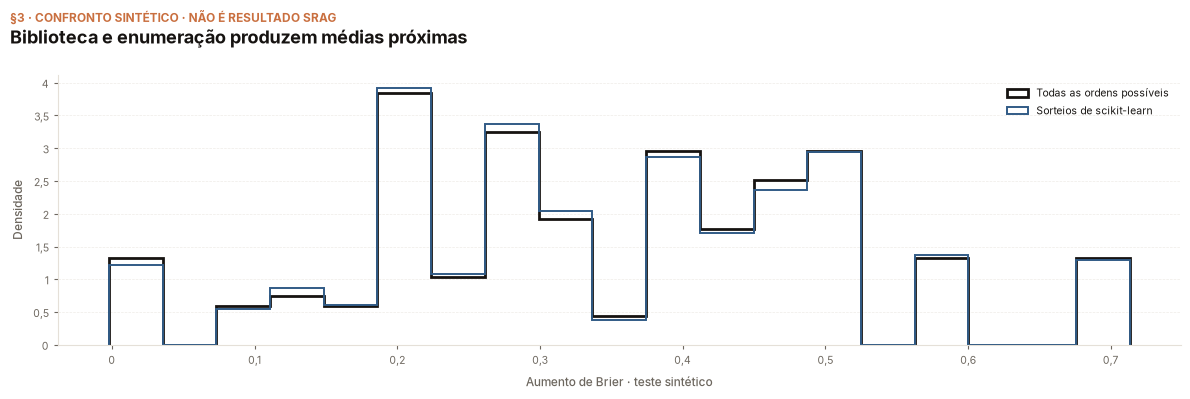

In [5]:
library_repeats = 6000
library = permutation_importance(
    model, x, y,
    scoring=lambda fitted, inputs, target: -brier_score_loss(
        target, fitted.predict_proba(inputs)[:, 1]
    ),
    n_repeats=library_repeats,
    random_state=RANDOM_STATE,
)
library_delta = library.importances[0]
library_mcse = library_delta.std(ddof=1) / np.sqrt(library_repeats)
mean_gap = abs(library_delta.mean() - exact_delta.mean())
assert mean_gap < 4 * library_mcse
np.testing.assert_allclose(library.importances_mean[0], library_delta.mean(), rtol=0, atol=0)
np.testing.assert_allclose(library.importances_std[0], library_delta.std(ddof=0), rtol=0, atol=0)
converted_sd = library.importances_std[0] * np.sqrt(library_repeats / (library_repeats - 1))
np.testing.assert_allclose(converted_sd, library_delta.std(ddof=1), rtol=0, atol=1e-15)
print("Sorteios independentes de scikit-learn:", SP.pt_int(library_repeats))
print("PFI média sintética exata:", SP.pt(exact_delta.mean(), 8))
print("PFI média de scikit-learn:", SP.pt(library_delta.mean(), 8))
print("Diferença absoluta entre médias:", SP.pt(mean_gap, 8))
print("Erro Monte Carlo da média da biblioteca:", SP.pt(library_mcse, 8))
print("Critério de conferência:", SP.pt_int(4), "vezes esse erro; critério atendido.")
print("SD de scikit-learn, ddof =", SP.pt_int(0), ":", SP.pt(library.importances_std[0], 8))
print("SD amostral após conversão, ddof =", SP.pt_int(1), ":", SP.pt(converted_sd, 8))
print("Conversão de SD confere com os sorteios individuais.")

fig, ax = plt.subplots(figsize=SP.FAIXA)
bins = np.linspace(min(exact_delta.min(), library_delta.min()), max(exact_delta.max(), library_delta.max()), 20)
ax.hist(exact_delta, bins=bins, density=True, histtype="step", linewidth=2, color=SP.ESCURO, label="Todas as ordens possíveis")
ax.hist(library_delta, bins=bins, density=True, histtype="step", linewidth=1.4, color=SP.AZUL, label="Sorteios de scikit-learn")
ax.set_xlabel("Aumento de Brier · teste sintético")
ax.set_ylabel("Densidade")
ax.legend(frameon=False)
SP.titulo(fig, "Biblioteca e enumeração produzem médias próximas", "§3 · CONFRONTO SINTÉTICO · NÃO É RESULTADO SRAG")
SP.salvar(fig, "pfi-internals-library")
display(fig)
plt.close(fig)


**O que olhar.** As médias concordam dentro do critério de Monte Carlo declarado. A conversão de SD é exata; não seria correto comparar a SD amostral da aula diretamente com o campo `importances_std` da biblioteca.

## §4 — Invariantes que uma média correta não garante

Uma segunda matriz sintética mistura categorias nativas, campos booleanos e números. Conferimos índice, tipos, níveis e as colunas que ficam fixas. O embaralhamento conjunto deve preservar as tuplas observadas; o restrito a subgrupos deve conservar o agrupamento de cada registro.

Um preditor de auditoria rejeita chamadas de treinamento. Suas probabilidades saem em precisão simples; a perda registra o tipo que recebe para conferir a conversão do núcleo. Esse preditor foi construído apenas para o teste.


In [6]:
categories = ["desconhecido", "nao", "sim"]
cx = pd.DataFrame({
    "heart": pd.Categorical(["sim", "nao", "desconhecido", "nao", "sim", "desconhecido"], categories=categories),
    "diabetes": pd.Categorical(["sim", "nao", "sim", "desconhecido", "nao", "desconhecido"], categories=categories),
    "fixed_bool": [True, False, True, False, True, False],
    "fixed_number": np.arange(6, dtype=np.int32),
}, index=[91, 2, 18, 4, 52, 9])
cy = np.array([1, 0, 0, 1, 0, 1])
cx_snapshot = cx.copy(deep=True)
cy_snapshot = cy.copy()
order = np.array([2, 4, 0, 5, 1, 3])

single = E.permutar_colunas(cx, "heart", order)
np.testing.assert_array_equal(single["heart"].to_numpy(), cx["heart"].to_numpy()[order])
pd.testing.assert_frame_equal(single.drop(columns="heart"), cx.drop(columns="heart"))
assert single.index.equals(cx.index)
assert single.dtypes.equals(cx.dtypes)
assert single["heart"].cat.categories.equals(cx["heart"].cat.categories)

joint_order = np.array([5, 0, 4, 1, 3, 2])
joint = E.permutar_colunas(cx, ("heart", "diabetes"), joint_order)
for column in ["heart", "diabetes"]:
    np.testing.assert_array_equal(joint[column].to_numpy(), cx[column].to_numpy()[joint_order])
assert not joint["diabetes"].equals(cx["diabetes"])
original_pairs = cx.groupby(["heart", "diabetes"], observed=False).size()
joint_pairs = joint.groupby(["heart", "diabetes"], observed=False).size()
pd.testing.assert_series_equal(joint_pairs, original_pairs)
pd.testing.assert_frame_equal(joint.drop(columns=["heart", "diabetes"]), cx.drop(columns=["heart", "diabetes"]))
# This explicit donor order stays in each original diabetes group.
np.testing.assert_array_equal(cx["diabetes"].to_numpy()[order], cx["diabetes"].to_numpy())
within = E.permutar_colunas(cx, "heart", order)
pd.testing.assert_series_equal(within.groupby(["heart", "diabetes"], observed=False).size(), original_pairs)
pd.testing.assert_series_equal(within["diabetes"], cx["diabetes"])

class AuditPredictor:
    def __init__(self):
        self.fit_calls = 0
        self.prediction_calls = 0
    def fit(self, *args, **kwargs):
        self.fit_calls += 1
        raise AssertionError("PFI não deve chamar fit.")
    def predict_proba(self, inputs):
        self.prediction_calls += 1
        probability = inputs["heart"].map({"nao": .1, "sim": .8, "desconhecido": .4}).astype(float).to_numpy(dtype=np.float32)
        return np.column_stack([1 - probability, probability])

probability_types = []
def audit_loss(target, probability):
    probability_types.append(probability.dtype)
    return float(np.mean((probability - target) ** 2))

audit_model = AuditPredictor()
cat_before, cat_after = E.trace_pfi(audit_model, cx, cy, "heart", [order, np.arange(len(cx))], audit_loss)
assert cat_after[-1] == cat_before
assert audit_model.fit_calls == 0
assert all(dtype == np.dtype("float64") for dtype in probability_types)
pd.testing.assert_frame_equal(cx, cx_snapshot)
np.testing.assert_array_equal(cy, cy_snapshot)
ignored_before, ignored_after = E.trace_pfi(audit_model, cx, cy, "fixed_number", [order, np.arange(len(cx))], audit_loss)
np.testing.assert_allclose(ignored_after, ignored_before, rtol=0, atol=0)
print("Tipos, níveis de categoria, índice e campos fixos: preservados.")
print("Tuplas preservadas no embaralhamento conjunto: verdadeiro.")
print("Subgrupos de diabetes preservados pela ordem restrita: verdadeiro.")
print("Mudança após restaurar a identidade:", SP.pt(cat_after[-1] - cat_before, 8))
print("Mudança da variável ignorada pelo preditor:", SP.pt(np.max(np.abs(ignored_after - ignored_before)), 8))
print("Chamadas de treinamento:", SP.pt_int(audit_model.fit_calls))
print("Todas as perdas receberam probabilidade float64:", all(dtype == np.dtype("float64") for dtype in probability_types))

invalid_cases = [
    ("heart", np.array([0, 0, 2, 3, 4, 5])),
    ("heart", np.array([0, 1, 2, 3, 4])),
    ("heart", np.array([0, 1, 2, 3, 4, 6])),
    ("heart", np.arange(len(cx), dtype=float)),
    ("missing", np.arange(len(cx))),
    (("heart", "heart"), np.arange(len(cx))),
    ((), np.arange(len(cx))),
]
rejected = 0
for columns, bad_order in invalid_cases:
    try:
        E.permutar_colunas(cx, columns, bad_order)
    except ValueError:
        rejected += 1
assert rejected == len(invalid_cases)
invalid_studies = [{"repeats": 0}, {"repeats": 1}, {"repeats": 2.5}, {"split": "train"}]
for kwargs in invalid_studies:
    try:
        P.study(WORK / "invalid-study", **kwargs)
    except ValueError:
        continue
    raise AssertionError("Contrato inválido deveria ser rejeitado antes do ajuste.")
print("Pedidos inválidos rejeitados pelo transporte:", SP.pt_int(rejected))
print("Pedidos inválidos rejeitados pelo estudo:", SP.pt_int(len(invalid_studies)))


Tipos, níveis de categoria, índice e campos fixos: preservados.
Tuplas preservadas no embaralhamento conjunto: verdadeiro.
Subgrupos de diabetes preservados pela ordem restrita: verdadeiro.
Mudança após restaurar a identidade: 0,00000000
Mudança da variável ignorada pelo preditor: 0,00000000
Chamadas de treinamento: 0
Todas as perdas receberam probabilidade float64: True
Pedidos inválidos rejeitados pelo transporte: 7
Pedidos inválidos rejeitados pelo estudo: 4


**O que olhar.** A variável ignorada não muda as probabilidades. Restaurar a identidade após um sorteio confirma que a perturbação não se acumula. O teste conjunto conserva os pares, enquanto o teste restrito conserva o grupo de cada destino; nenhum deles protege todas as relações com outras entradas.

## §5 — Conferir os registros reais que alimentam os slides

Agora lemos os resultados comprometidos de SRAG. Esta seção verifica integridade da amostra, ordens reproduzidas, sinais, médias, SD, erro Monte Carlo, ranks e equivalência entre diferença e razão. Não reexecuta o ajuste nem a busca de modelos. O walkthrough reconstrói o preditor e confere o traço real de idade.

A avaliação usa o modelo e o teste histórico fixos. A dispersão desses sorteios mede somente variação da permutação. O teste temporal já observado é exploratório.


In [7]:
gold_dir = REPO / "modules/00-dataset/gold"
record = json.loads((gold_dir / "pfi_ranking.json").read_text())
slides = json.loads((gold_dir / "pfi_slide_explainer.json").read_text())
protocol = record["protocol"]
assert protocol["repeats"] >= 2
assert protocol["split"] == "test"
sample_hash = hashlib.sha256((gold_dir / "gold_covid_obito_sample.parquet").read_bytes()).hexdigest()
assert sample_hash == protocol["sample_sha256"]
rng = np.random.default_rng(protocol["permutation_seed"])
record_orders = [rng.permutation(protocol["n_evaluation"]) for _ in range(protocol["repeats"])]
orders_hash = hashlib.sha256(np.asarray(record_orders).tobytes()).hexdigest()
assert orders_hash == protocol["permutation_orders_sha256"]
mean_discrepancies, sd_discrepancies = [], []
for row in record["rows"]:
    for metric, result in row["metrics"].items():
        after = np.asarray(result["after"])
        delta = np.asarray(result["delta"])
        direction = -1 if metric == "auc" else 1
        assert len(after) == protocol["repeats"]
        np.testing.assert_allclose(delta, direction * (after - record["original"][metric]), rtol=0, atol=1e-15)
        mean_discrepancies.append(abs(delta.mean() - result["mean"]))
        sd_discrepancies.append(abs(delta.std(ddof=1) - result["sd"]))
        np.testing.assert_allclose(result["after_mean"], after.mean(), rtol=0, atol=1e-15)
        np.testing.assert_allclose(result["after_sd"], after.std(ddof=1), rtol=0, atol=1e-15)
        np.testing.assert_allclose(result["mcse"], delta.std(ddof=1) / np.sqrt(len(delta)), rtol=0, atol=1e-15)
for metric in record["original"]:
    deltas = np.asarray([row["metrics"][metric]["delta"] for row in record["rows"]])
    ranks = pd.DataFrame(deltas).rank(ascending=False, method="average").to_numpy()
    rank_order = np.argsort(-deltas.mean(axis=1), kind="stable")
    for position, row_index in enumerate(rank_order):
        result = record["rows"][row_index]["metrics"][metric]
        assert result["rank"] == position + 1
        np.testing.assert_allclose(result["rank_repeats"], ranks[row_index], rtol=0, atol=0)
        np.testing.assert_allclose(result["rank_mean"], ranks[row_index].mean(), rtol=0, atol=1e-15)
        np.testing.assert_allclose(result["rank_sd"], ranks[row_index].std(ddof=1), rtol=0, atol=1e-15)
        assert result["top10_fraction"] == np.mean(ranks[row_index] <= 10)

baseline = record["original"]["brier"]
assert baseline > 0
for row in slides["rows"]:
    canonical = next(r for r in record["rows"] if r["feature"] == row["feature"])["metrics"]["brier"]
    assert row["before"] == baseline
    for slide_key, source_key in [("after_mean", "after_mean"), ("after_sd", "after_sd"), ("difference_mean", "mean"), ("difference_sd", "sd")]:
        np.testing.assert_allclose(row[slide_key], canonical[source_key], rtol=0, atol=1e-15)
    np.testing.assert_allclose(row["ratio_mean"], row["after_mean"] / baseline, rtol=0, atol=1e-15)
    np.testing.assert_allclose(row["ratio_sd"], row["difference_sd"] / baseline, rtol=0, atol=1e-15)
age = next(row for row in record["rows"] if row["feature"] == "idade_anos")["metrics"]["brier"]
np.testing.assert_allclose(slides["walkthrough"]["after"], age["after"], rtol=0, atol=0)
np.testing.assert_allclose(slides["walkthrough"]["difference"], age["delta"], rtol=0, atol=0)
for diagnostic in slides["dependence"]["results"]:
    after = np.asarray(diagnostic["after"])
    delta = np.asarray(diagnostic["difference"])
    assert len(after) == protocol["repeats"]
    np.testing.assert_allclose(delta, after - baseline, rtol=0, atol=1e-15)
    np.testing.assert_allclose(diagnostic["after_mean"], after.mean(), rtol=0, atol=1e-15)
    np.testing.assert_allclose(diagnostic["difference_mean"], delta.mean(), rtol=0, atol=1e-15)
    np.testing.assert_allclose(diagnostic["difference_sd"], delta.std(ddof=1), rtol=0, atol=1e-15)

print("SHA da amostra e SHA das ordens: conferem com o protocolo.")
print("Variáveis:", SP.pt_int(len(record["rows"])), "; métricas:", SP.pt_int(len(record["original"])), "; repetições:", SP.pt_int(protocol["repeats"]))
print("Ano do teste:", str(protocol["period"]), "; registros:", SP.pt_int(protocol["n_evaluation"]), "; óbitos:", SP.pt_int(protocol["events"]))
print("Semente registrada:", SP.pt_int(protocol["permutation_seed"]))
print("Maior discrepância de médias:", SP.pt(max(mean_discrepancies), 15))
print("Maior discrepância de SD:", SP.pt(max(sd_discrepancies), 15))
print("Resumos de gráficos conferidos:", SP.pt_int(len(slides["rows"])))
print("Diagnósticos de dependência conferidos:", SP.pt_int(len(slides["dependence"]["results"])))
print("Sinais e ranks conferidos para todas as métricas; traço de Age idêntico ao registro.")
print("Brier original SRAG:", SP.pt(baseline, 8))
print("Idade, PFI média ± SD:", SP.pt(age["mean"], 8), "±", SP.pt(age["sd"], 8))


import copy
import srag_72_pfi_presentation as Q
public = Q.project_aggregates(slides)
Q.validate_aggregates(public)
assert "preview" not in public
assert set(public["dependence"]) == {"results", "protocol"}
assert Q.project_aggregates({**slides, "unselected_example": {"patient": "must not ship"}}) == public
injected = copy.deepcopy(public)
injected["study"]["patient_example"] = {"probability": 0.9}
try:
    Q.validate_aggregates(injected)
except ValueError:
    pass
else:
    raise AssertionError("An extra nested field escaped the public projection.")
misreported = copy.deepcopy(public)
misreported["rows"][0]["difference_mean"] += .01
try:
    Q.validate_aggregates(misreported)
except ValueError:
    pass
else:
    raise AssertionError("An inconsistent displayed measurement was accepted.")
print("Projeção pública: campos individuais não selecionados; injeção e número inconsistente rejeitados.")


SHA da amostra e SHA das ordens: conferem com o protocolo.
Variáveis: 40 ; métricas: 3 ; repetições: 50
Ano do teste: 2024 ; registros: 16.142 ; óbitos: 2.945
Semente registrada: 42
Maior discrepância de médias: 0,000000000000000
Maior discrepância de SD: 0,000000000000000
Resumos de gráficos conferidos: 10
Diagnósticos de dependência conferidos: 4
Sinais e ranks conferidos para todas as métricas; traço de Age idêntico ao registro.
Brier original SRAG: 0,13080778
Idade, PFI média ± SD: 0,02344944 ± 0,00073672
Projeção pública: campos individuais não selecionados; injeção e número inconsistente rejeitados.


**O que olhar.** O confronto com os registros reais detecta divergência entre o que o estudo salvou e o que os slides mostram. Hashes conferem proveniência; não são um teste de qualidade clínica. A reprodução do ajuste e dos erros individuais pertence ao walkthrough, enquanto este internals verifica o núcleo por um caminho independente.

## §6 — O que o livro diz

**O que o livro diz.** Molnar define a importância pela mudança de perda de um modelo fixo ao permutar uma entrada. O diagnóstico depende da perda, do modelo e dos dados de avaliação. Repetir sorteios descreve sua variabilidade, sem incorporar sozinho a incerteza de novos pacientes ou de novos treinamentos.

Os testes confirmam a operação marginal e o transporte conjunto. O exemplo de subgrupos conserva a categoria de diabetes, mas pode romper outras relações. Não é PFI condicional dado todo o restante. A importância conjunta não é, por definição, a soma das importâncias individuais; comparar esses números isoladamente não demonstra interação, redundância ou causalidade.


In [8]:
assert max(mean_discrepancies) < 1e-15
assert max(sd_discrepancies) < 1e-15
checks = pd.DataFrame([
    {"confronto": "Núcleo × oráculo posicional independente", "resultado": "passou"},
    {"confronto": "Distribuição exata × scikit-learn", "resultado": "passou no critério Monte Carlo"},
    {"confronto": "SD populacional × SD amostral", "resultado": "conversão conferida"},
    {"confronto": "Categorias, pares, grupos, alvos e ausência de fit", "resultado": "preservados"},
    {"confronto": "Registros reais × resumos da aula", "resultado": "conferem em precisão completa"},
])
print(SP.tabela(checks))


                                         confronto                      resultado
          Núcleo × oráculo posicional independente                         passou
                 Distribuição exata × scikit-learn passou no critério Monte Carlo
                     SD populacional × SD amostral            conversão conferida
Categorias, pares, grupos, alvos e ausência de fit                    preservados
                 Registros reais × resumos da aula  conferem em precisão completa


## Fechamento — O método está no transporte e na perda

O núcleo compartilhado movimenta apenas as entradas escolhidas. O modelo não aprende novamente, e os desfechos permanecem nos destinos originais. As validações independentes dão suporte ao código, preservando a distinção entre experimento sintético, resultado SRAG e interpretação científica.

[Voltar ao walkthrough](pfi_walkthrough.ipynb) · [Ficha técnica histórica do experimento](../../00-dataset/PFI.md)


**Referências.** Molnar (2025), *Interpretable Machine Learning*, capítulo 23 — Permutation Feature Importance; scikit-learn, *Permutation feature importance* e API de `permutation_importance`; Breiman (2001), *Random Forests*. Entradas completas e links no [README do módulo](../README.md).
